In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input,SimpleRNN,Dense,Embedding

In [2]:
sentences = [
 "I love this product",
 "This movie made me smile",
 "Service was friendly and quick",
 "Today felt bright and happy",
 "This is the best day",
 "Absolutely fantastic experience",
 "I enjoyed every single moment",
 "Great job, well done",
 "The food tasted delicious",
 "Totally recommend to everyone",
 "Very satisfied with results",
 "This worked better than expected",
 "Amazing quality and value",
 "Such a pleasant surprise",
 "I feel positive about this",
 "I hate this product",
 "This movie bored me",
 "Service was rude and slow",
 "Today was cold and lonely",
 "This is the worst day",
 "Terrible experience overall",
 "I regret buying this",
 "Very disappointed with results",
 "The food tasted awful",
 "Do not recommend this",
 "It broke after one use",
 "Not worth the money",
 "Utterly frustrating and annoying",
 "I feel negative about this",
 "Such a waste of time",
]
labels = [1]*15 + [0]*15
labels = np.array(labels)

In [3]:
vocab_size = 1000
tok = Tokenizer(num_words=vocab_size,oov_token= '<OOV>')
tok.fit_on_texts(sentences)
seq = tok.texts_to_sequences(sentences)
maxlen = max(len(s) for s in seq)
x = pad_sequences(seq,maxlen=maxlen,padding='post')
y = labels

In [4]:
emb_feature = 8
rnn_unit = 4

In [7]:
from os import name
inp = Input(shape=(maxlen,),dtype='int32',name='input')
emb = Embedding(input_dim=vocab_size,output_dim=emb_feature,mask_zero=True,name='embedding')(inp)
rnn = SimpleRNN(units=rnn_unit,name='rnn')(emb)
out = Dense(units=1,activation='sigmoid',name='output')(rnn)
model = Model(inputs=inp,outputs=out)
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 5)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 5, 8)      │      8,000 │ input[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 5)         │          0 │ input[0][0]       │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn (SimpleRNN)     │ (None, 4)         │         52 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │          5 │ rnn[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,057 (31.47 KB)

 Trainable params: 8,057 (31.47 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(x,y,epochs=25,batch_size=8,verbose=1)

Epoch 1/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4333 - loss: 0.6962
Epoch 2/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5667 - loss: 0.6852
Epoch 3/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6667 - loss: 0.6768
Epoch 4/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7333 - loss: 0.6687
Epoch 5/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8333 - loss: 0.6595
Epoch 6/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8667 - loss: 0.6502 
Epoch 7/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8667 - loss: 0.6412
Epoch 8/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8667 - loss: 0.6319
Epoch 9/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8667 - loss: 0.6216
Epoch 10/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9333 - loss: 0.6109
Epoch 11/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9333 - loss: 0.6004
Epoch 12/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9333 - loss: 0.5883


In [11]:
loss, accuracy = model.evaluate(x, y, verbose=0)
print(f"Final Loss: {loss:.4f}")
print(f"Final Accuracy: {accuracy * 100:.2f}%")

Final Loss: 0.4072
Final Accuracy: 100.00%


In [12]:
# 1. Write new sentences to test
test_sentences = [
    "I really love this",
    "Worst experience ever",
    "Food was delicious and great",
    "Terrible quality waste of money",
    "Not bad at all"
]

# 2. Convert words -> IDs -> padded matrix of shape (5, maxlen)
# (Note: replace 'tok' with your tokenizer variable name if you named it differently)
test_seqs = tok.texts_to_sequences(test_sentences)
test_padded = pad_sequences(test_seqs, maxlen=maxlen, padding='post')

# 3. Get probability predictions (numbers between 0.0 and 1.0)
predictions = model.predict(test_padded)

# 4. Print readable results
for sentence, prob in zip(test_sentences, predictions):
    score = prob[0]
    label = "Positive (1)" if score >= 0.5 else "Negative (0)"
    print(f"'{sentence}'  -->  {label}  (confidence: {score:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step
'I really love this'  -->  Positive (1)  (confidence: 0.5352)
'Worst experience ever'  -->  Negative (0)  (confidence: 0.4159)
'Food was delicious and great'  -->  Positive (1)  (confidence: 0.6645)
'Terrible quality waste of money'  -->  Negative (0)  (confidence: 0.2691)
'Not bad at all'  -->  Negative (0)  (confidence: 0.3852)


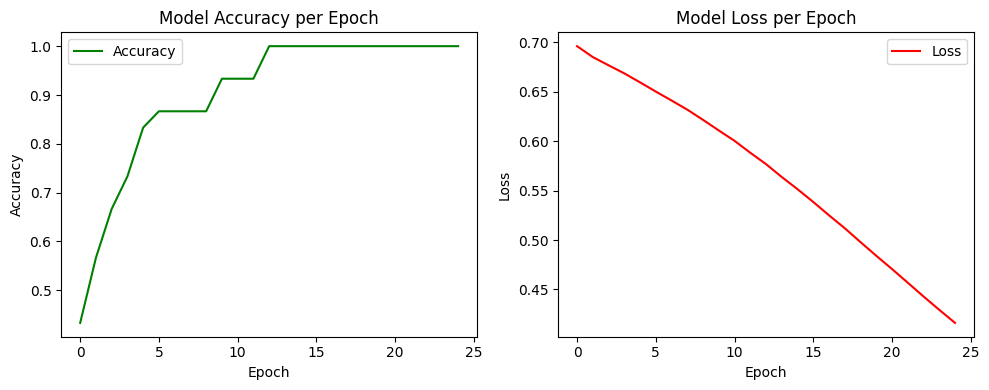

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Accuracy', color='green')
plt.title('Model Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss', color='red')
plt.title('Model Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
def predict_sentiment(texts):
    # Allow passing either a single string or a list of strings
    if isinstance(texts, str):
        texts = [texts]

    # 1. Automatic Preprocessing
    seqs = tok.texts_to_sequences(texts)
    padded = pad_sequences(seqs, maxlen=maxlen, padding='post')

    # 2. Automatic Prediction (verbose=0 hides the progress bar clutter)
    probs = model.predict(padded, verbose=0)

    # 3. Formatted Output
    for text, prob in zip(texts, probs):
        score = prob[0]
        label = "Positive (1)" if score >= 0.5 else "Negative (0)"
        print(f"'{text}'  -->  {label}  (confidence: {score:.4f})")

In [15]:
predict_sentiment("I love her")
predict_sentiment(["Great service and friendly staff", "Total waste of money"])

'I love her'  -->  Positive (1)  (confidence: 0.5651)
'Great service and friendly staff'  -->  Positive (1)  (confidence: 0.6242)
'Total waste of money'  -->  Negative (0)  (confidence: 0.3033)
